# Retention: users, customers and revenue

Three views of the same question, "do people stay?":

1. **User retention.** Of the people who sign up, how many are still using the product weeks later?
2. **Customer survival.** Of the workspaces that start paying, how long do they keep paying?
3. **Revenue retention.** Of last year's MRR, how much is still here, including upgrades?

Every number is read from the warehouse's governed tables (`metrics.kpi_user_retention_cohorts`,
`core.fct_mrr_monthly`, `metrics.kpi_revenue_retention`), using the definitions in
`docs/metrics_spec.md`, section 4.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analysis.warehouse import query

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEGMENT_COLORS = {"SMB": "#8a8f98", "Mid-Market": "#2f6fdb", "Enterprise": "#0b8a5f"}
AS_OF = pd.Timestamp("2026-09-30")

## 1. User retention by signup cohort

Week N counts users active at any point in days 7N to 7N+6 after their own signup. Cells that haven't
fully happened yet are left blank instead of being shown as low retention.

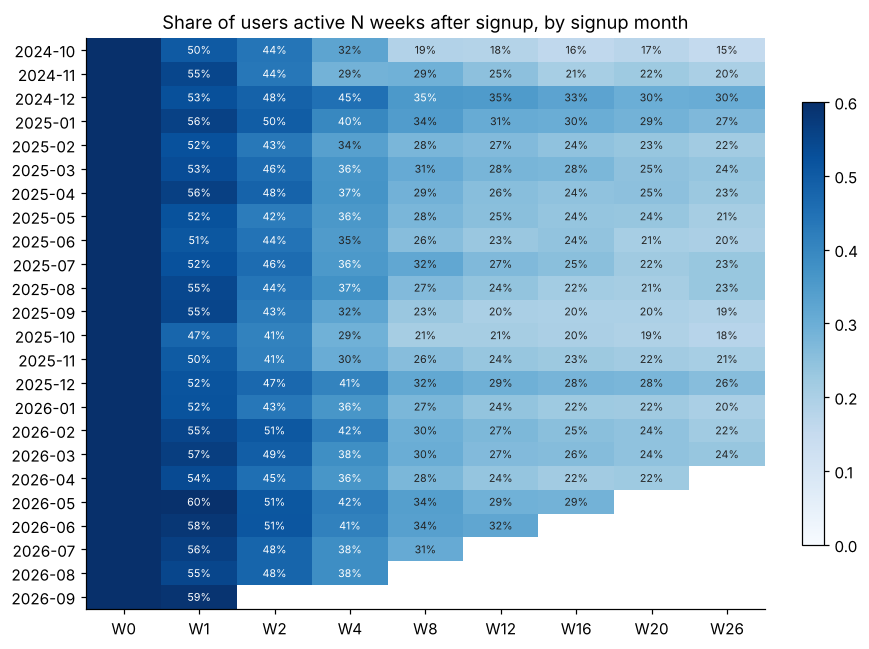

In [2]:
cohorts = query("select * from metrics.kpi_user_retention_cohorts")
# The first ISO week starts on 30 Sep 2024, the day before launch; count it as October.
cohorts["signup_month"] = pd.to_datetime(cohorts["signup_week"]).clip(lower="2024-10-01").dt.to_period("M")

complete = cohorts[cohorts["is_complete"]]
grid = (complete.groupby(["signup_month", "week_number"])[["active_users", "cohort_users"]].sum()
        .eval("active_users / cohort_users").unstack())
shown = [0, 1, 2, 4, 8, 12, 16, 20, 26]
grid = grid[shown]

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(grid.values, aspect="auto", cmap="Blues", vmin=0, vmax=0.6)
ax.set_xticks(range(len(shown)), [f"W{w}" for w in shown])
ax.set_yticks(range(len(grid)), [str(p) for p in grid.index])
for (i, j), v in np.ndenumerate(grid.values):
    if not np.isnan(v) and j > 0:
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.35 else "#222")
ax.set_title("Share of users active N weeks after signup, by signup month")
fig.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()

The pattern is stable from cohort to cohort: about half of new users come back in week 1, and the
curve flattens after week 8 at roughly 20 to 25%. No cohort stands out as broken, which matters
because it means the averages below aren't hiding a bad month.

segment,SMB,Mid-Market,Enterprise
week_number,,,
1.000000,46%,56%,69%
4.000000,25%,40%,58%
12.000000,14%,29%,47%
26.000000,12%,24%,42%


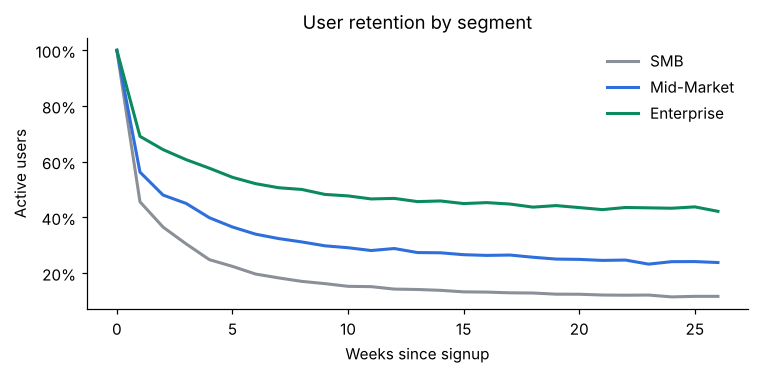

In [3]:
by_seg = (complete[complete["segment"].isin(SEGMENT_COLORS)]
          .groupby(["segment", "week_number"])[["active_users", "cohort_users"]].sum()
          .eval("active_users / cohort_users").unstack(0))

fig, ax = plt.subplots(figsize=(7, 3.5))
for seg, color in SEGMENT_COLORS.items():
    ax.plot(by_seg.index, by_seg[seg], color=color, lw=2, label=seg)
ax.set_xlabel("Weeks since signup")
ax.set_ylabel("Active users")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(frameon=False)
ax.set_title("User retention by segment")
plt.tight_layout()
by_seg.loc[[1, 4, 12, 26], list(SEGMENT_COLORS)].style.format("{:.0%}")

## 2. Activation predicts retention

Workspace owners who reach activation (first report within 7 days) are compared with those who don't.
This is the link that makes activation a sensible primary metric for the onboarding A/B test.

,activated,not activated
week,,
1,76.6%,19.5%
4,48.4%,2.4%
12,23.3%,0.6%
26,18.9%,0.4%


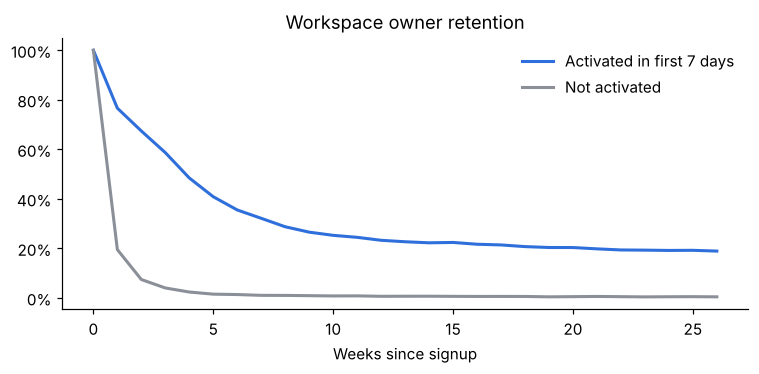

In [4]:
owners = query('''
    select u.user_id, u.signup_date, a.is_activated
    from core.dim_user as u
    inner join core.dim_account as a on u.account_id = a.account_id
    where u.role = 'owner' and not u.is_internal
''')
activity = query("select user_id, activity_date from core.fct_user_daily_activity")
act = activity.merge(owners, on="user_id")
act["week"] = (pd.to_datetime(act["activity_date"]) - pd.to_datetime(act["signup_date"])).dt.days // 7
owners["weeks_observed"] = (AS_OF - pd.to_datetime(owners["signup_date"])).dt.days // 7

rows = []
for week in range(0, 27):
    eligible = owners[owners["weeks_observed"] > week]
    active = set(act.loc[act["week"] == week, "user_id"])
    rate = eligible.assign(active=eligible["user_id"].isin(active)).groupby("is_activated")["active"].mean()
    rows.append({"week": week, "activated": rate.get(True), "not activated": rate.get(False)})
curve = pd.DataFrame(rows).set_index("week")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(curve.index, curve["activated"], color="#2f6fdb", lw=2, label="Activated in first 7 days")
ax.plot(curve.index, curve["not activated"], color="#8a8f98", lw=2, label="Not activated")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Weeks since signup")
ax.legend(frameon=False)
ax.set_title("Workspace owner retention")
plt.tight_layout()
curve.loc[[1, 4, 12, 26]].style.format("{:.1%}")

Owners who don't activate are almost all gone within a month; activated owners keep coming back. This
is a correlation, not proof that activation *causes* retention (keener users do both), but together
with the experiment it makes activation the right lever to push.

## 3. How long do customers keep paying?

A Kaplan-Meier survival curve over paying accounts. Accounts still paying today are *censored*: we know
they've lasted at least this long, not when they'll leave. Ignoring that, for example by averaging the
tenure of churned accounts only, would badly understate customer lifetime.

,still paying after 6 months,still paying after 12 months,still paying after 18 months
SMB,86%,72%,60%
Mid-Market,94%,84%,77%
Enterprise,98%,95%,95%


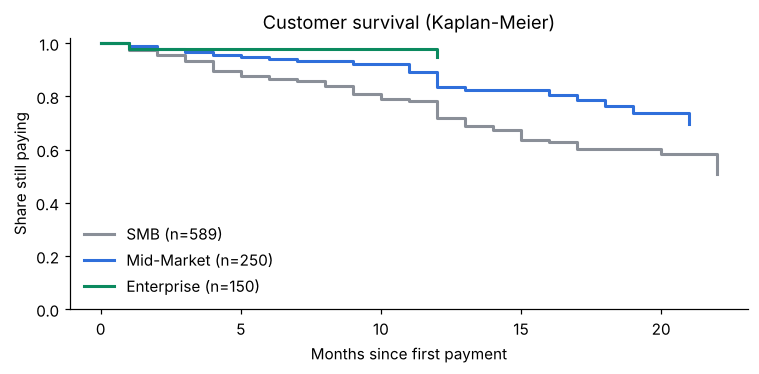

In [5]:
mrr = query('''
    select m.account_id, m.month_start, m.mrr_usd, m.movement, a.segment
    from core.fct_mrr_monthly as m
    inner join core.dim_account as a on m.account_id = a.account_id
''')
first_paid = mrr[mrr["mrr_usd"] > 0].groupby("account_id")["month_start"].min()
first_churn = mrr[mrr["movement"] == "churned"].groupby("account_id")["month_start"].min()
last_month = mrr["month_start"].max()

spells = pd.DataFrame({"start": first_paid}).join(first_churn.rename("churn"))
spells["churned"] = spells["churn"].notna()
end = spells["churn"].fillna(last_month)
spells["months"] = ((end.dt.year - spells["start"].dt.year) * 12 + end.dt.month - spells["start"].dt.month
                    + (~spells["churned"]).astype(int))
spells = spells.join(mrr.groupby("account_id")["segment"].first())


def kaplan_meier(durations, events):
    t = np.sort(np.unique(durations[events]))
    at_risk = np.array([(durations >= x).sum() for x in t])
    died = np.array([((durations == x) & events).sum() for x in t])
    return pd.Series(np.cumprod(1 - died / at_risk), index=t)


fig, ax = plt.subplots(figsize=(7, 3.5))
summary = {}
for seg, color in SEGMENT_COLORS.items():
    s = spells[spells["segment"] == seg]
    km = kaplan_meier(s["months"].to_numpy(), s["churned"].to_numpy())
    km = pd.concat([pd.Series([1.0], index=[0]), km])
    ax.step(km.index, km.values, where="post", color=color, lw=2, label=f"{seg} (n={len(s)})")
    summary[seg] = {f"still paying after {m} months": km[km.index <= m].iloc[-1] for m in (6, 12, 18)}
ax.set_ylim(0, 1.02)
ax.set_xlabel("Months since first payment")
ax.set_ylabel("Share still paying")
ax.legend(frameon=False)
ax.set_title("Customer survival (Kaplan-Meier)")
plt.tight_layout()
pd.DataFrame(summary).T.style.format("{:.0%}")

Enterprise customers almost never leave; SMB customers churn steadily from the first month. The step
pattern in Mid-Market and Enterprise comes from annual plans, which can only churn at renewal.

## 4. Revenue retention

Logo retention counts customers, gross revenue retention (GRR) counts only losses, and net revenue
retention (NRR) adds expansion back. All three compare each account with itself 12 months earlier, in
constant currency.

,logo_retention,gross_revenue_retention,net_revenue_retention
segment,,,
SMB,66%,63%,82%
Mid-Market,80%,75%,99%
Enterprise,96%,95%,104%


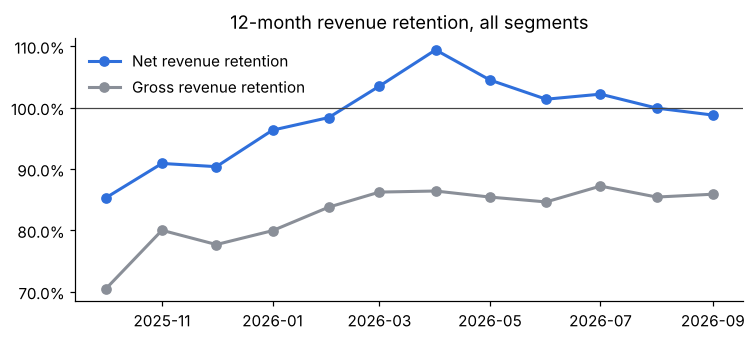

In [6]:
rr = query("select * from metrics.kpi_revenue_retention")
total = rr.groupby("month_start")[["mrr_12m_ago_usd", "gross_retained_mrr_usd", "net_retained_mrr_usd"]].sum()
total["GRR"] = total["gross_retained_mrr_usd"] / total["mrr_12m_ago_usd"]
total["NRR"] = total["net_retained_mrr_usd"] / total["mrr_12m_ago_usd"]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(total.index, total["NRR"], color="#2f6fdb", lw=2, marker="o", label="Net revenue retention")
ax.plot(total.index, total["GRR"], color="#8a8f98", lw=2, marker="o", label="Gross revenue retention")
ax.axhline(1, color="#444", lw=0.8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(frameon=False)
ax.set_title("12-month revenue retention, all segments")
plt.tight_layout()

latest = rr[(rr["month_start"] == rr["month_start"].max()) & rr["segment"].isin(SEGMENT_COLORS)].set_index("segment")
latest[["logo_retention", "gross_revenue_retention", "net_revenue_retention"]].loc[list(SEGMENT_COLORS)].style.format("{:.0%}")

## Takeaways

- **Week 1 is where users are won or lost.** About half of signups never return after their first week,
  and owners who don't activate are almost all gone within a month. Onboarding is the highest-leverage
  place to work, which the checklist experiment confirms.
- **Retention is a segment story.** Enterprise users and customers retain far better than SMB at every
  level: users, logos and revenue. Blended numbers hide this, which is why every KPI table in the
  warehouse carries segment.
- **Net revenue retention is around 100%**: expansion from growing teams roughly offsets churn. Enterprise
  is above 100% and SMB well below. The lever for NRR is SMB churn, not more expansion.
- **Survival analysis, not averages.** Most customers who ever paid are still paying, so any lifetime
  value estimate must treat them as censored. Averaging the tenure of churned accounts alone would
  describe only the customers who left early.